In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score

import matplotlib.pyplot as plt

C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
# Create models
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000)
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [7]:
 # Train models
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [8]:
# Get predicted probabilities
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

In [9]:
# Calculate ROC values
logistic_fpr, logistic_tpr, _ = roc_curve(y_test, logistic_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

Logistic Regression AUC: 0.9953703703703703
Random Forest AUC: 0.9937169312169312


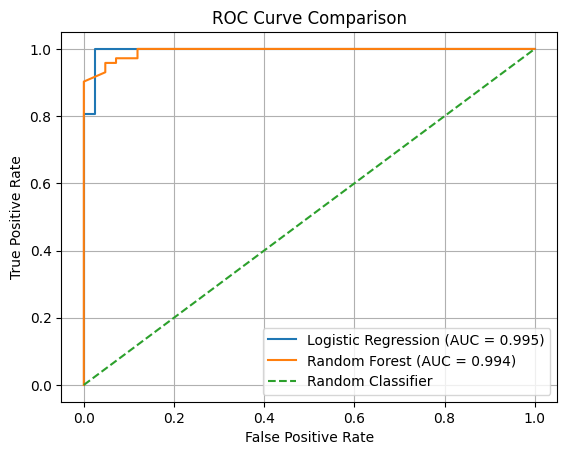

In [11]:
# Calculate AUC scores
logistic_auc = roc_auc_score(y_test, logistic_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

print("Logistic Regression AUC:", logistic_auc)
print("Random Forest AUC:", rf_auc)

# Plot both ROC curves
plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Logistic Regression (AUC = {logistic_auc:.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()